# Inladen van data gemeten met phyphox

De metingen die je hebt gedaan met phyphox gaan we nu inladen. 

**Belangrijk** : In dit bestand is er vanuit gegaan dat je de data hebt opgeslagen als csv file met delimiter komma en decimaal punt (csv (comma, decimal point)).


**Belangrijk** : Restart de kernel nadat als je een andere data file wilt inladen. Dit voorkomt dat je dadelijk een grafiek krijgt bij bijvoorbeeld barometer terwijl dit niet in je huidige data set zit. Dit komt omdat je data nog in het python geheugen zit van jouw vorige dataset die wel bijvoorbeeld barometer heeft.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Inladen en plotten van de ruwe meetgegeven en roteren naar het referentiekader van het karretje
Dit is een voorbeeld gemaakt door Wim Bouwman met stukken code van TA's van 2025.
In dit voorbeeld zitten vooral tijdsperiodes die voor het gebruik moeten worden aangepast. 

## Het inladen van data met numpy (stappenplan)

Voor je de data kan verwerken moeten we deze eerst inladen. Dit kan met behulp van de numpy functie loadtxt.
Deze pakt een csv (in principe neemt het elke file met text er in aan) en plaatst alles in een array. De delimiter zorgt er voor dat loadtxt weet na welk teken (in dit geval een komma) het volgende getal of stuk text komt (Voor de geintereseerde: als je je csv opent met een text editor dan zie je tussen elk meet punt een komma)

**1**
Het is belangrijk dat je het volledig pad naar je data file invult bij filename of dat je csv file in dezelfde map staat als de notebook. Anders kan je computer het file niet vinden. 

**2**
De eerste rij bevat alleen text, deze wordt appart ingeladen. Deze kan je uitprinten om te kijken welke grootheden zijn gemeten. Voor acceleratie zul je zien dat dit tijd en acceleratie in de x,y,z richting bevat. 

**3**
Vanaf de eerste rij staat de nuttige data. Deze worden als kollomen ingeladen. Python (en c) werken sneller als rij, dus de data word van kollomen naar rijen geschreven door het te transponeren. 

**4** 
De data staat nu nog bij elkaar, maar we willen apparte arrays, zodat je ze kan plotten. Met behulp van de header kan je kijken welke rij hoort bij welke grootheid. In de meeste gevallen staat de tijd eerst, dus met data[0] pak je de eerste rij. (let op, python telt vanaf 0)

**5**
Nu je de data hebt ingeladen en gesoorteerd per grootheid kan je gaan plotten. 




## Accelerometer

['"Time (s)"' '"X (m/s^2)"' '"Y (m/s^2)"' '"Z (m/s^2)"']


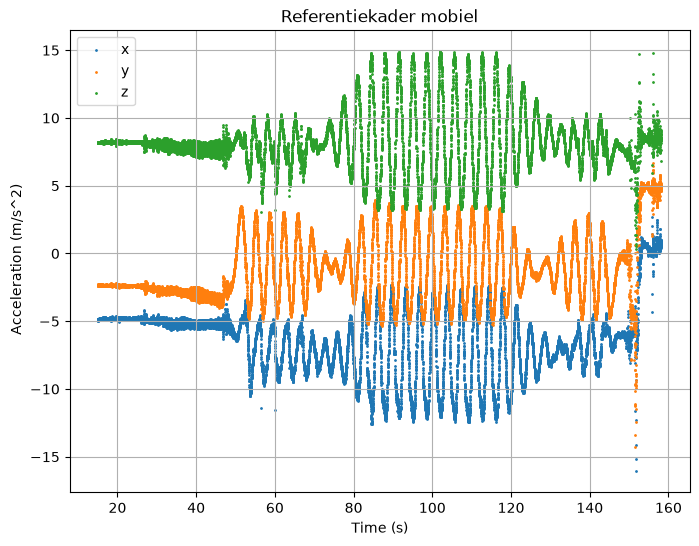

<Figure size 640x480 with 0 Axes>

In [3]:

#inladen van data
#1
#eerst geef je het relevante bestand aan
fileName = r'Drievliet - Marte 2 2026-09-25 14-33-49\Accelerometer.csv' #zorg dat je hier het juiste pad naar je csv file zet.

#2
#dan laad je de eerste rij in, dit is een header met de namen van de grootheden
header = np.loadtxt(fileName, delimiter=',', max_rows=1, dtype=str)
print(header)  #index van de header geeft aan om welke grootheid het gaat. dit is handig voor het plotten

#3
#daarna laad je de rest van de data in. 
data = np.loadtxt(fileName, delimiter=',', skiprows=1)
data = data.T  #getransponeerd zodat we met rijen werken in plaats van met colommen, dit is sneller in python (en c).
#selecteer relevante tijdsperiode, dit kan je aanpassen voor jouw data. Hier wordt alles verwijderd waar de tijd kleiner is dan 15 seconden of groter dan 70 seconden.
data = data[:,(data[0] > 15) & (data[0] < 250)]  #verwijder rijen waar de tijd 0 is
#4
#De data is nu nog een 2d array. Elke rij is een grootheid, elke kolom een meetpunt.
#we halen de rijen eruit zodat we ze makkelijk kunnen plotten
#je kan dit aanpassen voor jouw data, maar voor acceleratie en zwaarte kracht is dit goed. 
dataTime = data[0]  #eerste rij is tijd
dataAccX = data[1]  #tweede rij is acceleratie in x richting
dataAccY = data[2]  #derde rij is acceleratie in y richting
dataAccZ = data[3]  #vierde rij is acceleratie in z richting

#5
#plotten van data
plt.figure(figsize=(8, 6))



plt.scatter(dataTime, dataAccX, s=1, label='x')
plt.scatter(dataTime, dataAccY, s=1, label='y')
plt.scatter(dataTime, dataAccZ, s=1, label='z')
plt.xlabel('Time (s)')
plt.ylabel(' Acceleration (m/s^2)')
plt.title('Referentiekader mobiel')
plt.legend()
plt.grid(True)
plt.show()

from model import prep_folder
import pathlib
prep_folder("processed_plots")

plt.savefig(pathlib.Path("processed_plots") / "accelerometer_mobiel.png")

## Roteren zwaartekracht naar z

[-4.78942671 -2.36212461  8.22394059]


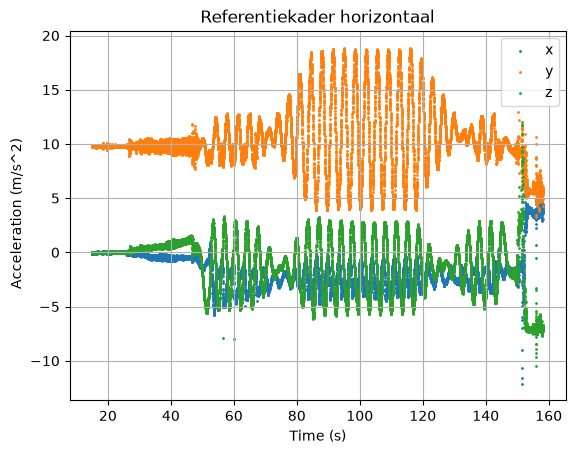

<Figure size 640x480 with 0 Axes>

In [6]:
# Werkt handiger om alle versnellingen in een array te zetten, zodat we makkelijk kunnen rekenen met de data.
Aphone= np.vstack((dataAccX,dataAccY,dataAccZ))
# Hieronder selecteer je een tijdsperiode waarin de telefoon stil ligt. In dit geval is dat tussen de 15 en 20 seconden.
trest= (data[0] > 15) & (data[0] < 25)
Arest= np.mean(Aphone[:,trest],axis=1)
print(Arest)
x= Arest[0]
y= Arest[1]
z= Arest[2]
ryz=np.sqrt(y**2+z**2)
# Nu volgt de rotatie om de x-as, zodat de y component vanwege de zwaartekracht naar z draait.
Rx = np.array([[1,0,0],[0,z/ryz,-y/ryz],[0,y/ryz,z/ryz]])
r=np.sqrt(x**2+y**2+z**2)
# Nu volgt de rotatie om de y-as, zodat de z component vanwege de zwaartekracht naar z draait.
Ry = np.array([[ryz/r,0,-x/r],[0,1,0],[x/r,0,ryz/r]])

# Het model dat ik probeer te fitten heeft de verticaal als y, dus we draaien de boel nog eens 90 graden.
Rx_minus90 = np.array([
    [1,  0,  0],
    [0,  0,  1],
    [0, -1,  0]
])

Ahorizontal = Rx_minus90 @ Ry @ Rx @ Aphone
plt.scatter(dataTime, Ahorizontal[0], s=1, label='x')
plt.scatter(dataTime, Ahorizontal[1], s=1, label='y')
plt.scatter(dataTime, Ahorizontal[2], s=1, label='z')
plt.xlabel('Time (s)')
plt.ylabel(' Acceleration (m/s^2)')
plt.title('Referentiekader horizontaal')
plt.legend()
plt.grid(True)
plt.show()
plt.savefig(pathlib.Path("processed_plots") / "accelerometer_horizontaal.png")

We zien nu hierboven dat het goed gelukt is om in de periodes van rust de zwaartekracht alleen in z te laten werken. Je ziet aan het einde van de meting dat de x en y component niet helemaal 0 zijn, wat laat zien dat de telefoon een beetje gedraaid is tijdens de rit. Het kan dus beter.

### Roteren van x naar voren

[ 5.56994065 -6.23131201  9.773867  ]


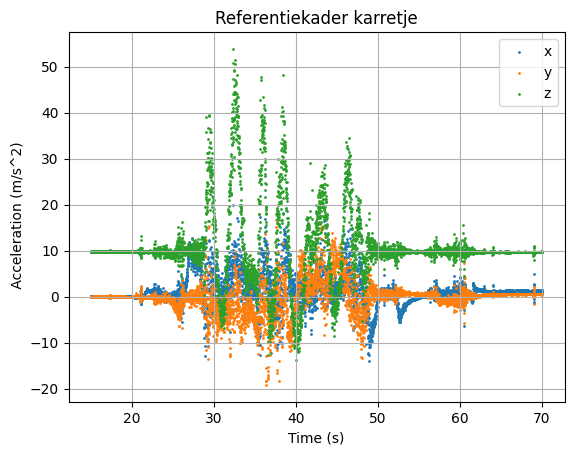

In [10]:
# Hieronder selecteer je een tijdsperiode waarin het karretje recht naar voren gaat. In dit geval is dat tussen de 27 en 28.2 seconden.
tfor= (data[0] > 27) & (data[0] < 28.2)
Afor= np.mean(Ahorizontal[:,tfor],axis=1)
print(Afor)
xp= Afor[0]
yp= Afor[1]
zp= Afor[2]
rxy=np.sqrt(xp**2+yp**2)
# Nu volgt de rotatie om de z-as, zodat de y component van de voorwaartse versnelling naar x draait.
Rz = np.array([[xp/rxy,yp/rxy,0],[-yp/rxy,xp/rxy,0],[0,0,1]])
Acar = Rz @ Ahorizontal
plt.scatter(dataTime, Acar[0], s=1, label='x')  
plt.scatter(dataTime, Acar[1], s=1, label='y')
plt.scatter(dataTime, Acar[2], s=1, label='z')
plt.xlabel('Time (s)')
plt.ylabel(' Acceleration (m/s^2)')
plt.title('Referentiekader karretje')
plt.legend()
plt.grid(True)
plt.show()

Het roteren is blijkbaar gelukt. In de richtingen met alleen voorwaartse versnelling zie je alleen componenten in de x-richting.

## Gyroscoop inlezen en roteren
Ik vermoed dat dezelfde rotatiematrix kan worden losgelaten op de gyroscoopmetingen. Ik zit niet goed genoeg in dit soort wiskunde om dit met zekerheid te zeggen, maar de resultaten zien er goed uit. Neem dit dus met een korreltje zout.
### Gyroscoop inlezen

['"Time (s)"' '"X (rad/s)"' '"Y (rad/s)"' '"Z (rad/s)"']


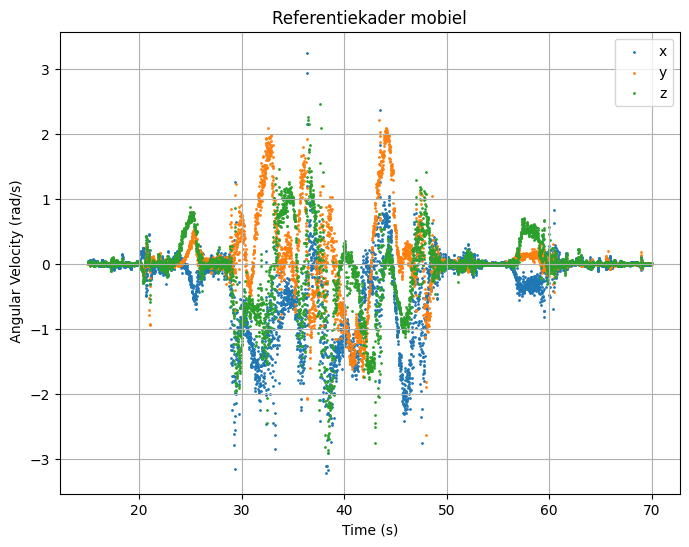

In [11]:
fileName = 'FormX2026/Gyroscope.csv' #zorg dat je hier het juiste pad naar je csv file zet.
header = np.loadtxt(fileName, delimiter=',', max_rows=1, dtype=str)
print(header)  #index van de header geeft aan om welke grootheid het gaat. dit is handig voor het plotten
data = np.loadtxt(fileName, delimiter=',', skiprows=1)
data = data.T  #getransponeerd zodat we met rijen werken in plaats van met colommen, dit is sneller in python (en c).
#selecteer relevante tijdsperiode, dit kan je aanpassen voor jouw data. Hier wordt alles verwijderd waar de tijd kleiner is dan 15 seconden of groter dan 70 seconden.
data = data[:,(data[0] > 15) & (data[0] < 70)]  #verwijder rijen waar de tijd 0 is
Time = data[0]  #eerste rij is tijd
gyroX = data[1]  #tweede rij is gyroscoop in x richting
gyroY = data[2]  #derde rij is gyroscoop in y richting
gyroZ = data[3]  #vierde rij is gyroscoop in z richting

plt.figure(figsize=(8, 6))
plt.scatter(Time, gyroX, s=1, label='x')
plt.scatter(Time, gyroY, s=1, label='y')
plt.scatter(Time, gyroZ, s=1, label='z')
plt.xlabel('Time (s)')
plt.ylabel(' Angular Velocity (rad/s)')
plt.title('Referentiekader mobiel')
plt.legend()
plt.grid(True)
plt.show()

### Roteren

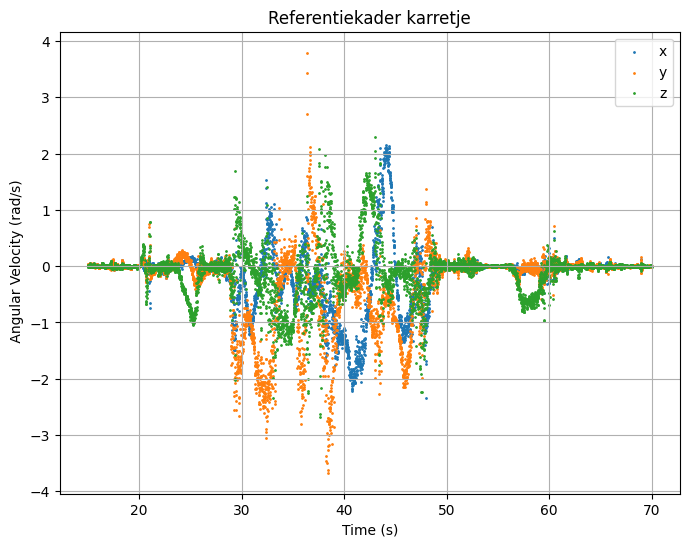

In [15]:
Gyr= np.vstack((gyroX,gyroY,gyroZ))
GyrCar = Rz @ Ry @ Rx @ Gyr
plt.figure(figsize=(8, 6))
plt.scatter(Time, GyrCar[0], s=1, label='x')
plt.scatter(Time, GyrCar[1], s=1, label='y')
plt.scatter(Time, GyrCar[2], s=1, label='z')
plt.xlabel('Time (s)')
plt.ylabel(' Angular Velocity (rad/s)')
plt.title('Referentiekader karretje')
plt.legend()
plt.grid(True)
plt.show()  


Dit ziet er redelijk uit. Bij 26 seconden is de bocht naar rechts die de dip in z geeft. Op het oog geintegreert komt deze uit op $\pi/2$. Tijdens de bocht is er een lichte val naar beneden die de wiebel in y reflecteert. Daarna komt de looping van 29-36 seconden die je ziet als een grote dubbele dip in y. Als je deze grof op het oog integreert, kom je uit op $2 \pi$ radialen. Op het laatst bij 58 seconden is er de laatste schone bocht naar rechts die je in z ziet.